## ElasticNet Regression

In [ ]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Lasso, Ridge,LinearRegression , ElasticNet
import pandas as pd
from sklearn.metrics import r2_score
from sklearn.impute import KNNImputer
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#import SBGclass of sklearn

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

x, y = load_diabetes(return_X_y=True)

train_x, test_x, train_y, test_y = train_test_split(x, y, test_size=0.2, random_state=42)

#### Applying ElasticNet Regressor using skLearn 

* First is the ElaticNet Class by skLearn with two hyperparameter. [ratio = 1 is pure Lasso ][ratio = 0 is pure Ridge].

* Second we can use with SDG Class with penalty parameter. by setting l1 , l2 elasticnet

In [208]:
#ElasticNet Regression
elnet = ElasticNet(alpha=0.005, l1_ratio=0.9)
elnet.fit(train_x, train_y)

elnet_pred = elnet.predict(test_x)
r2_score(test_y, elnet_pred)

0.46192536271651097

In [209]:
#Linear Regression
linreg = LinearRegression()
linreg.fit(train_x, train_y)

linreg_pred = linreg.predict(test_x)
r2_score(test_y, linreg_pred)

0.45260276297191937

In [210]:
#Ridge Regression
ridge = Ridge(alpha=0.005)
ridge.fit(train_x, train_y)
ridge_pred = ridge.predict(test_x)
r2_score(test_y, ridge_pred)

0.45507917389239994

In [211]:
#Lasso Regression
lasso = Lasso(alpha=0.005)
lasso.fit(train_x, train_y)
lasso_pred = lasso.predict(test_x)
r2_score(test_y, lasso_pred)  

0.45567569556409904

## 21st Century Bordeaux Wine Dataset

**_Let's take a high dimensional data for testing each algorithm perfomrance._**

*   Dropped the `Name` Column.
*   Remove $ from price and log transformed as the target is left skewed.
*   989 features.

In [212]:
df = pd.read_csv('/Users/abheetsharma/Downloads/BordeauxWines.csv')

df.drop_duplicates(inplace=True)
df.drop(columns=["Name" , "Year"], inplace=True)

df["Price"] = (
    df["Price"]
    .astype("string")
    .replace("$NA", pd.NA)
    .str.replace("$", "", regex=False)
)

df["Price"] = pd.to_numeric(df["Price"], errors="coerce")


In [213]:
df.isnull().sum()

#Use KNN imputer to fill the missing values in the dataset

knn_imputer = KNNImputer(n_neighbors=5)
df['Price'] = pd.DataFrame(knn_imputer.fit_transform(df[['Price']]), columns=['Price'])


In [214]:
df['Price'] = df['Price'].round(2).astype('float')

df['Price']

0         20.00
1         29.00
2         49.66
3         49.66
4         20.00
5         49.66
6         49.66
7         10.00
8         49.66
9         14.00
10        49.66
11        35.00
12        22.00
13        49.66
14        49.66
15        28.00
16        49.66
17        65.00
18        49.66
19        25.00
20        49.66
21        49.66
22        49.66
23        25.00
24        75.00
25        49.66
26        49.66
27        44.00
28        35.00
29        33.00
30        49.66
31        26.00
32        25.00
33        49.66
34        26.00
35        50.00
36        20.00
37        49.66
38        49.66
39        35.00
40        49.66
41        47.00
42        25.00
43        28.00
44        19.00
45        49.66
46        27.00
47        50.00
48        16.00
49        30.00
50        49.66
51        49.66
52        21.00
53        49.66
54        69.00
55        90.00
56        57.00
57        33.00
58        49.66
59        49.66
60        27.00
61        49.66
62      

<Axes: xlabel='Price', ylabel='Count'>

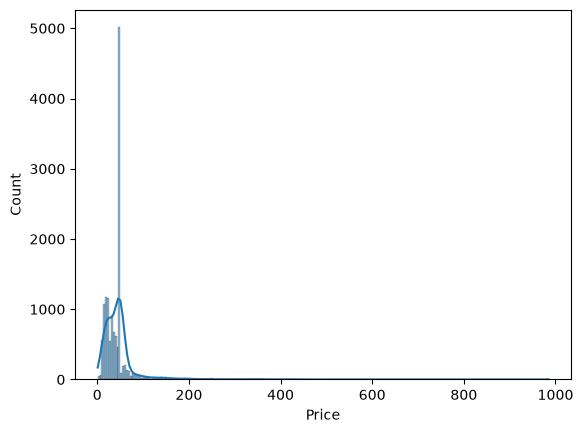

In [215]:
sns.histplot(data=df, x='Price', kde=True)

In [216]:
# Log transformation of the Price column to reduce skewness
df['Price'] = np.log1p(df['Price'])

<Axes: xlabel='Price', ylabel='Count'>

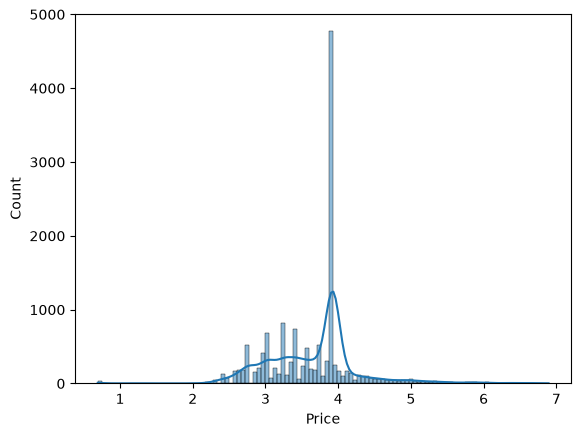

In [217]:
sns.histplot(data=df, x='Price', kde=True)

In [218]:
x = df.drop(columns=['Price'])
y = df['Price']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [219]:
lr = LinearRegression()
lr.fit(x_train, y_train)
y_pred = lr.predict(x_test)
r2_score(y_test, y_pred)

0.1742448110657726

In [220]:
rr = Ridge(alpha=45)
rr.fit(x_train, y_train)
y_pred_ridge = rr.predict(x_test)
r2_score(y_test, y_pred_ridge)

0.23170874091064786

In [226]:
ls = Lasso(alpha=0.005)
ls.fit(x_train, y_train)
y_pred_lasso = ls.predict(x_test)
r2_score(y_test, y_pred_lasso)  

# print(ls.coef_.shape)

0.20453921031199784

In [230]:
el = ElasticNet(alpha=0.006, l1_ratio=0.6)
el.fit(x_train, y_train)
y_pred_elastic = el.predict(x_test)
r2_score(y_test, y_pred_elastic)

0.2074929276292652